# Tweet Dataset Analysis

In [7]:
# Data handling libraries
import json
import numpy as np
import pandas as pd
from pandas import json_normalize
from pathlib import Path

# Scikit-learn modeling libraries
from sklearn.dummy import DummyClassifier # For baseline model
from sklearn.feature_extraction.text import TfidfVectorizer # To convert text to numbers
from sklearn.linear_model import LogisticRegression # The classifier model
from sklearn.metrics import accuracy_score, classification_report # For evaluation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score # For splitting and validating
from sklearn.pipeline import Pipeline # To chain processing steps

## Data preprocessing

In [16]:
# Load the training data from a JSON Lines file (one JSON object per line)
train_data = pd.read_json('../data/train.jsonl', lines=True)
# The tweet data is nested. json_normalize flattens the nested JSON into columns.
train_data = json_normalize(train_data.to_dict(orient='records'))

# Load the Kaggle test data (which we will make predictions on)
kaggle_data = pd.read_json('../data/kaggle_test.jsonl', lines=True)
# Also normalize the Kaggle data
kaggle_data = json_normalize(kaggle_data.to_dict(orient='records'))


# Separate features from the target variable for the training set
X_train = train_data.drop('label', axis=1)
y_train = train_data['label']

X_kaggle = kaggle_data

In [17]:
# Define a function to get the full text from a tweet object.
# Tweets can be truncated, storing the full version in 'extended_tweet.full_text'.
def extract_full_text(tweet):
    # Start with the standard 'text' field
    text = tweet['text']
    # Check if the 'extended_tweet.full_text' field exists (is not NaN)
    if not pd.isna(tweet['extended_tweet.full_text']):
        # If it exists, it's the full text, so use it instead
        text = tweet['extended_tweet.full_text']
    return text

# Apply this function to every row (axis=1) in the training data
X_train['full_text'] = X_train.apply(lambda tweet: extract_full_text(tweet), axis=1)
# Apply the same function to the Kaggle test data
X_kaggle['full_text'] = X_kaggle.apply(lambda tweet: extract_full_text(tweet), axis=1)

texts = X_train["full_text"].astype(str)
labels = y_train.astype(int)

test_texts = X_kaggle["full_text"].astype(str)

## Data visualization

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

### Feature extraction

#### Raw features

In [103]:
tweet_len = X_train['full_text'].map(lambda s: len(s) if s else 0)
user_desc_len = X_train['user.description'].map(lambda s: len(s) if s else 0)
reply_count = X_train['reply_count'].fillna(0)
retweet_count = X_train['retweet_count'].fillna(0)

statuses_count = X_train['user.statuses_count'].fillna(0)
listed_count = X_train['user.listed_count'].fillna(0)
favorites_count = X_train['user.favourites_count'].fillna(0)

quote_favorites_count = X_train['quoted_status.favorite_count'].fillna(0)
quote_follow_count = X_train['quoted_status.user.followers_count'].fillna(0)
quote_statuses_count = X_train['quoted_status.user.statuses_count'].fillna(0)
quote_listed_count = X_train['quoted_status.user.listed_count'].fillna(0)


#### Engineered features

In [104]:
listed_to_active_ratio = listed_count / (favorites_count + 1)

In [109]:
engagement_efficiency = (retweet_count + favorites_count) / (statuses_count + 1)

In [110]:
stats = pd.DataFrame({
    "Tweet length": tweet_len,
    "User description length": user_desc_len,
    
    "Statuses count": statuses_count,
    "Listed count": listed_count,
    "Favorites count": favorites_count,

    "Quoted tweet favorites count": quote_favorites_count,
    "Quoted user followers count": quote_follow_count,
    "Quoted user statuses count": quote_statuses_count,
    "Quoted user listed count": quote_listed_count,

    "Listed to active ratio": listed_to_active_ratio,
    "Engagement efficiency": engagement_efficiency,

    "label": y_train,
})

### Statuses count

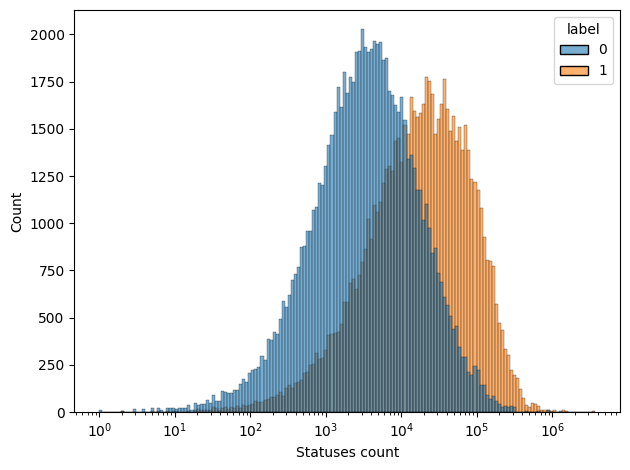

In [93]:
sns.histplot(
    stats, x="Statuses count", hue="label",
    label="Statuses count", log_scale=True,
    alpha=0.6,
)
plt.tight_layout()

### Listed count

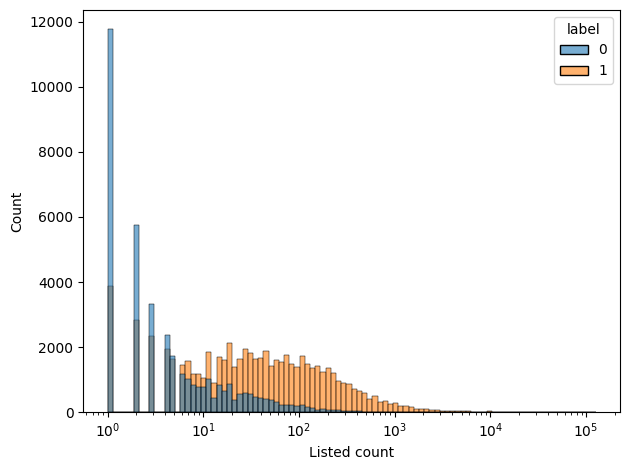

In [94]:
sns.histplot(
    stats, x="Listed count", hue="label",
    label="Listed count", log_scale=True,
    alpha=0.6,
)
plt.tight_layout()

### Favorites count

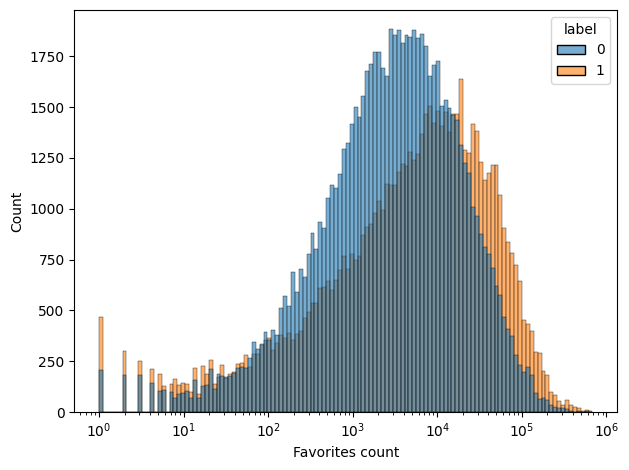

In [106]:
sns.histplot(
    stats, x="Favorites count", hue="label",
    label="Favorites count", log_scale=True,
    alpha=0.6,
)
plt.tight_layout()

### Listed to active ratio

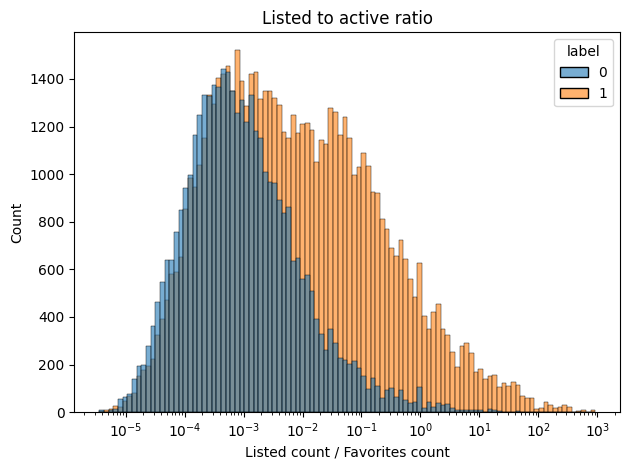

In [108]:
sns.histplot(
    stats, x="Listed to active ratio", hue="label",
    log_scale=True,
    alpha=0.6,
)
plt.xlabel("Listed count / Favorites count")
plt.title("Listed to active ratio")
plt.tight_layout()

### Engagement efficiency

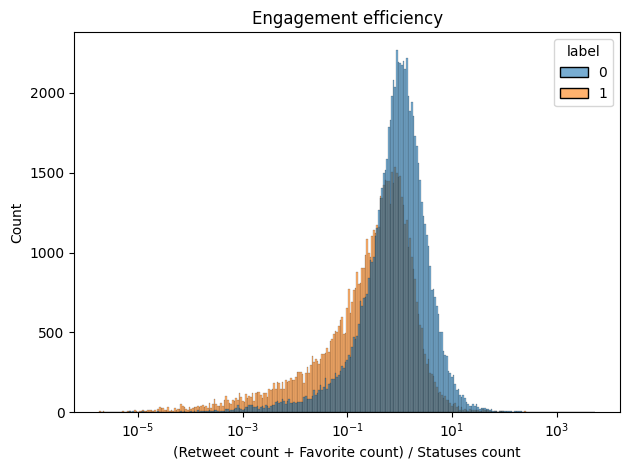

In [112]:
sns.histplot(
    stats, x="Engagement efficiency", hue="label",
    log_scale=True,
    alpha=0.6,
)
plt.xlabel("(Retweet count + Favorite count) / Statuses count")
plt.title("Engagement efficiency")
plt.tight_layout()

### Text length

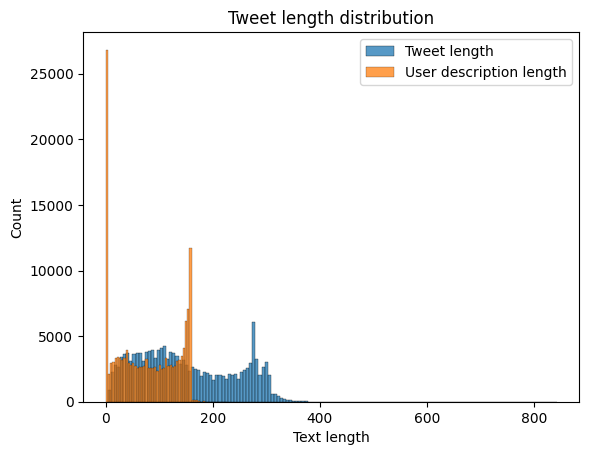

In [92]:
ax = plt.axes()
sns.histplot(stats, x="Tweet length", ax=ax, label="Tweet length")
sns.histplot(stats, x="User description length", ax=ax, label="User description length")
plt.xlabel("Text length")
plt.title("Tweet length distribution")
plt.legend();

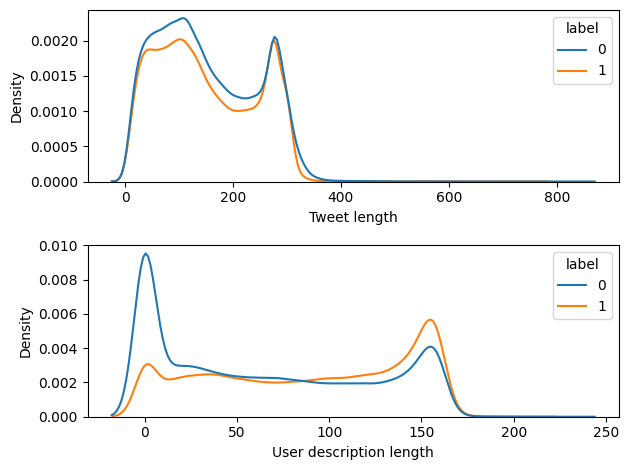

In [ ]:
fig, axes = plt.subplots(2)

sns.kdeplot(
    stats, x="Tweet length", hue="label",
    ax=axes[0], label="Tweet length",
)
sns.kdeplot(stats, x="User description length", hue="label",
 ax=axes[1], label="User description length",
)

fig.tight_layout()

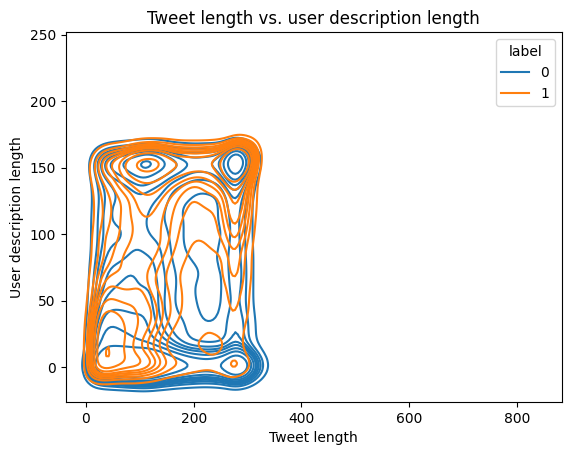

In [ ]:

sns.kdeplot(stats, x="Tweet length", y="User description length", hue="label")
plt.title("Tweet length vs. user description length");

### Quoted user followers count

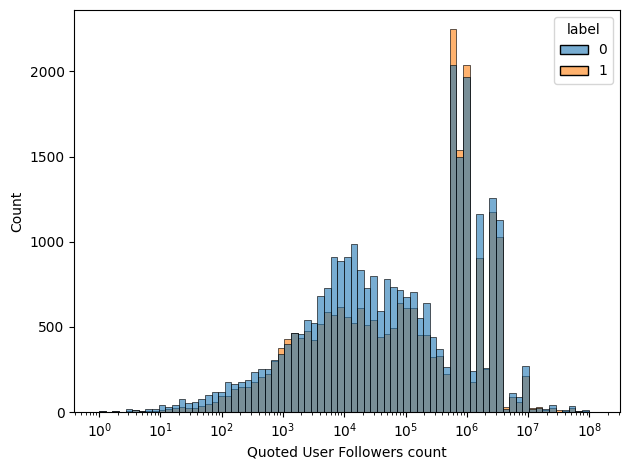

In [64]:

sns.histplot(
    stats, x="Quoted User Followers count", hue="label",
    label="Quoted User Followers count", log_scale=True,
    alpha=0.6,
)
plt.tight_layout()

### Quoted user statuses count

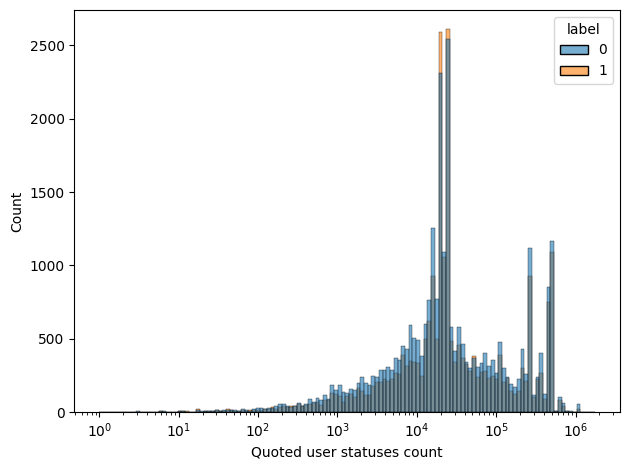

In [95]:

sns.histplot(
    stats, x="Quoted user statuses count", hue="label",
    label="Quoted user statuses count", log_scale=True,
    alpha=0.6,
)
plt.tight_layout()

### Quoted tweet favorites count

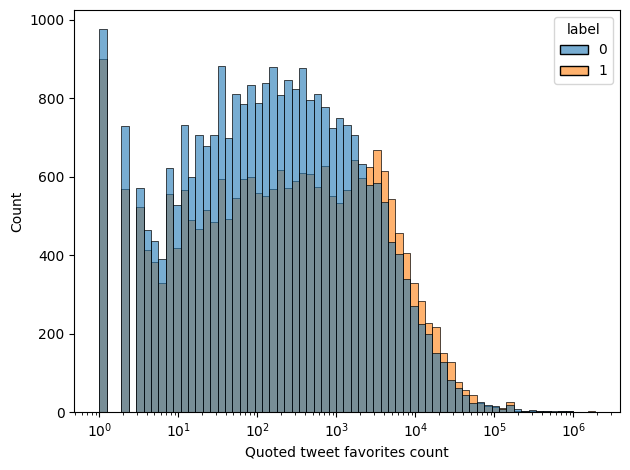

In [98]:

sns.histplot(
    stats, x="Quoted tweet favorites count", hue="label",
    label="Quoted tweet favorites count", log_scale=True,
    alpha=0.6,
)
plt.tight_layout()

### Quoted user listed count

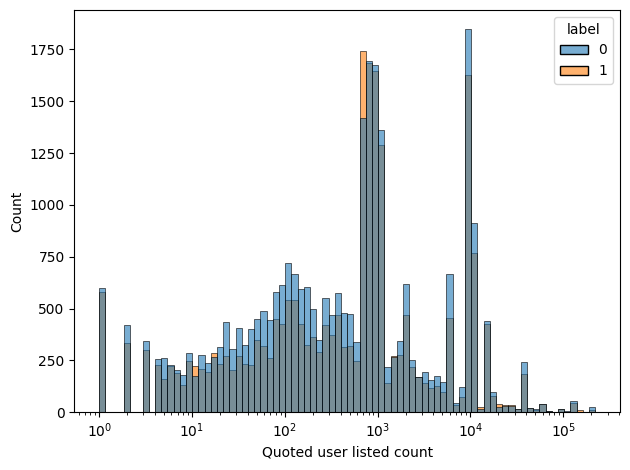

In [99]:

sns.histplot(
    stats, x="Quoted user listed count", hue="label",
    label="Quoted user listed count", log_scale=True,
    alpha=0.6,
)
plt.tight_layout()